# Flujo y transporte: visualización y análisis.

**Descripción**.

En esta notebook se recupera y se visualiza la información de la simulación de flujo de agua subterránea y transporte conservativo de la componente $U = c_1 - c_2$, donde $c_1= SO_4^{2-}$ y  $c_2 =  Ca^{2+}$. 

<a href="https://github.com/luiggix/RTWMA">RTWMA</a> © 2024-2026 by <a href="https://www.geofisica.unam.mx">IGF-UNAM</a> is licensed under <a href="https://creativecommons.org/licenses/by-nc/4.0/">CC BY-NC 4.0</a><img src="https://mirrors.creativecommons.org/presskit/icons/cc.svg" alt="" style="max-width: 1em;max-height:1em;margin-left: .2em;"><img src="https://mirrors.creativecommons.org/presskit/icons/by.svg" alt="" style="max-width: 1em;max-height:1em;margin-left: .2em;"><img src="https://mirrors.creativecommons.org/presskit/icons/nc.svg" alt="" style="max-width: 1em;max-height:1em;margin-left: .2em;">

# Recuperación de la información.

La función `vis.data_recovery()` del módulo [**src_01/vis.py**](src_01/vis.py) permite recuperar la información de los cálculos. Esta función requiere de los objetos de los modelos de flujo y transporte, los cuales se pueden crear a partir de los archivos de resultados como sigue.

In [1]:
from src_01 import vis
import flopy

In [2]:
## ---> Usamos LaTeX para los tectos de la figura.
import matplotlib.pyplot as plt
plt.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",  # Uses standard Computer Modern font
    "font.serif": ["Computer Modern Roman"],
})

Todos los resultados están almacenados en los subdirectorios `io_mf6/U/gwf` y `io_mf6/U/gwt`, esa información se utiliza para construir los objetos de los modelos de flujo y transporte.

In [3]:
## ---> Cargamos el modelo de flujo
o_sim_f = flopy.mf6.MFSimulation.load(
    sim_ws="io_mf6/U/gwf",
    verbosity_level=0,
)

## ---> Cargamos el modelo de transporte
o_sim_t = flopy.mf6.MFSimulation.load(
    sim_ws="io_mf6/U/gwt",
    verbosity_level=0,
)

## ---> Obtenemos los objetos de cada modelo
o_gwf = o_sim_f.get_model("flow")
o_gwt = o_sim_t.get_model("transport")

La función `vis.data_recovery()` recibe los objetos `o_gwf` y `o_gwt` para recuperar la información de los modelos.

In [4]:
x, head, qx, qy, U, times_c = vis.data_recovery(o_gwf, o_gwt)


Carga hidráulica
――――――――――――――――
 xcoord = ―― INIT xcoord ――
        = [ 0.5  1.5  2.5  3.5  4.5  5.5  6.5  7.5  8.5  9.5 10.5 11.5 12.5 13.5
 14.5 15.5 16.5 17.5 18.5 19.5 20.5 21.5 22.5 23.5 24.5 25.5 26.5 27.5
 28.5 29.5]
        = ―― END xcoord ――
times_h = ―― INIT times_h ――
        = [40.]
        = ―― END times_h ――
   head = ―― INIT head ――
        = [6.8 6.6 6.4 6.2 6.  5.8 5.6 5.4 5.2 5.  4.8 4.6 4.4 4.2 4.  3.8 3.6 3.4
 3.2 3.  2.8 2.6 2.4 2.2 2.  1.8 1.6 1.4 1.2 1. ]
        = ―― END head ――
     qx = ―― INIT qx ――
        = [[0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2
  0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2]]
        = ―― END qx ――
――――――――――――――――

Concentración
―――――――――――――
xcoord = ―― INIT xcoord ――
       = [ 0.5  1.5  2.5  3.5  4.5  5.5  6.5  7.5  8.5  9.5 10.5 11.5 12.5 13.5
 14.5 15.5 16.5 17.5 18.5 19.5 20.5 21.5 22.5 23.5 24.5 25.5 26.5 27.5
 28.5 29.5]
       = ―― END xcoord ――
 times = ―― INIT times ――
       = [ 1.  2. 

La función `vis.plot()` recibe toda la información necesaria para generar la visualización de los resultados:

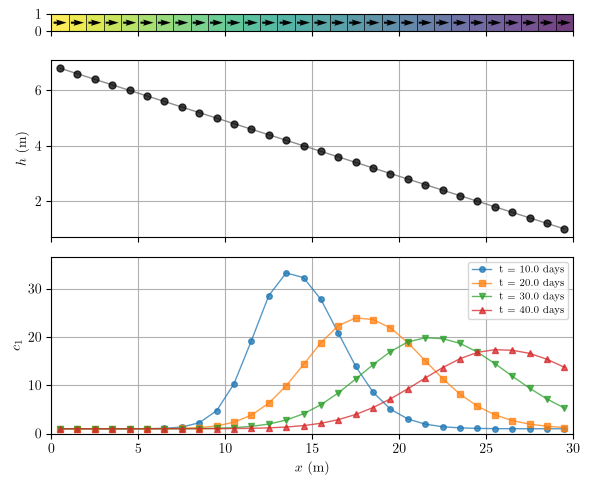

In [5]:
vis.plot(o_gwf, x, head, qx, qy, U, times_c)

Finalmente, la función `vis.plot_obs()` muestra la concentración en los puntos de observación `(5, 11, 12, 30)` como función del tiempo:

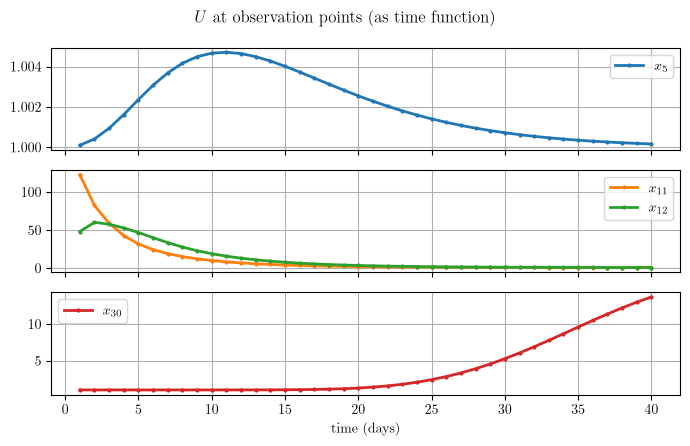

In [6]:
vis.plot_obs(U, times_c)